# Módulo 10: Ascenso del Oleaje (*Run-up*) y Cota Total de Inundación (`sedmor.runup`)

Este cuaderno incorpora al paquete los modelos empíricos y semiteóricos clásicos de **ascenso máximo del oleaje ($R_{2\%}$)** sobre playas naturales y estructuras costeras en talud, basados íntegramente en formulaciones abiertas de la literatura científica.

### Objetivos de aprendizaje
1. Evaluar el **número de Iribarren** ($\xi_0$) y el régimen de rotura frente a la pendiente de playa (`iribarren_number`).
2. Comparar los modelos de *run-up* en playas naturales: **Stockdon et al. (2006)**, **Holman (1986)**, **Mase (1989)**, **Nielsen y Hanslow (1991)** y **Hunt (1959)**, analizando la descomposición entre *setup* y *swash* incidente/infragravitatorio.
3. Dimensionar el ascenso **$R_{u2\%}$ sobre defensas y escolleras** mediante el manual **EurOtop (2018)** (`runup_eurotop`) y obtener la **cota total de inundación (*TWL*)** (`total_water_level`).


In [1]:
import numpy as np
import matplotlib.pyplot as plt
import sedmor as sm

plt.rcParams["figure.dpi"] = 110
print(f"Librería sedmor v{sm.__version__} con módulo sedmor.runup listo.")


Librería sedmor v0.1.0 con módulo sedmor.runup listo.


## 1. Comparación de Modelos en Playas Naturales y Descomposición de Stockdon (2006)

Para una tormenta costera ($H_{s0} = 3.5\,\text{m}$, $T_p = 11\,\text{s}$), evaluamos cómo crece el ascenso $R_{2\%}$ cuando la pendiente de playa pasa de **disipativa** ($\tan\beta = 0.015$) a **reflejante** ($\tan\beta = 0.20$), y descomponemos las contribuciones de *setup* y *swash*.


Longitud profunda L0 = 188.9 m | Rango Iribarren xi0: 0.11 a 1.47
En tan(beta)=0.06 -> Stockdon R2%=1.69 m | Holman=1.98 m


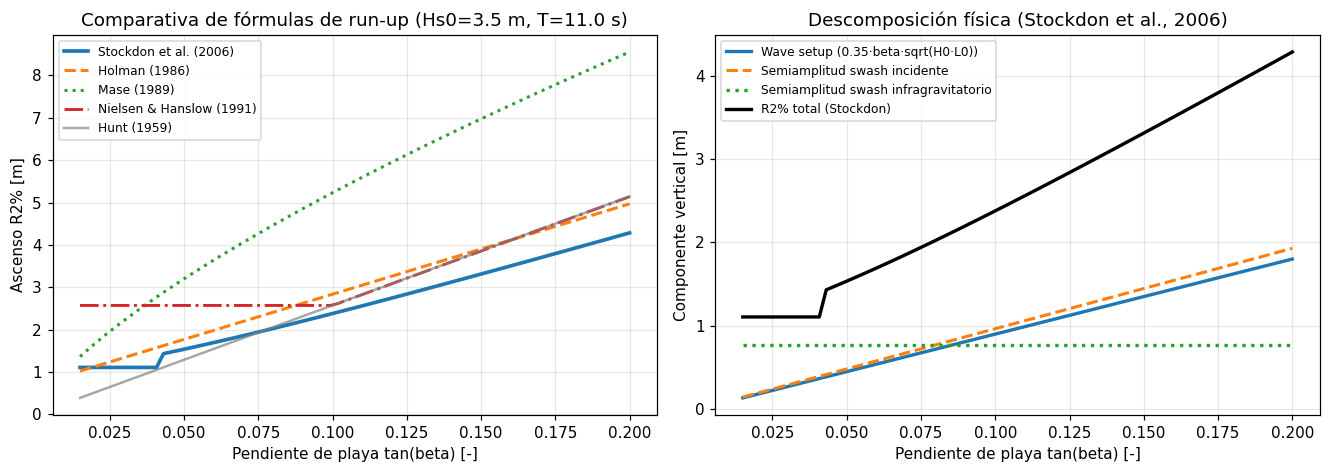

In [2]:
slopes = np.linspace(0.015, 0.20, 80)
Hs0_storm = 3.5
T_storm = 11.0

ib = sm.runup.iribarren_number(Hs0_storm, T_storm, slopes)
st = sm.runup.runup_stockdon(Hs0_storm, T_storm, slopes)
ho = sm.runup.runup_holman(Hs0_storm, T_storm, slopes)
ma = sm.runup.runup_mase(Hs0_storm, T_storm, slopes)
nh = sm.runup.runup_nielsen_hanslow(Hs0_storm / np.sqrt(2.0), T_storm, slopes)
hu = sm.runup.runup_hunt(Hs0_storm, T_storm, slopes)

print(f"Longitud profunda L0 = {float(np.asarray(st.L0).flat[0]):.1f} m | Rango Iribarren xi0: {ib.iribarren[0]:.2f} a {ib.iribarren[-1]:.2f}")
print(f"En tan(beta)=0.06 -> Stockdon R2%={np.interp(0.06, slopes, st.R2_percent):.2f} m | Holman={np.interp(0.06, slopes, ho.R2_percent):.2f} m")

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12.2, 4.4))

ax1.plot(slopes, st.R2_percent, lw=2.4, label="Stockdon et al. (2006)")
ax1.plot(slopes, ho.R2_percent, "--", lw=2.0, label="Holman (1986)")
ax1.plot(slopes, ma.R2_percent, ":", lw=2.0, label="Mase (1989)")
ax1.plot(slopes, nh.R2_percent, "-.", lw=1.9, label="Nielsen & Hanslow (1991)")
ax1.plot(slopes, hu.R2_percent, color="gray", alpha=0.7, lw=1.6, label="Hunt (1959)")
ax1.set_xlabel("Pendiente de playa tan(beta) [-]")
ax1.set_ylabel("Ascenso R2% [m]")
ax1.set_title(f"Comparativa de fórmulas de run-up (Hs0={Hs0_storm} m, T={T_storm} s)")
ax1.grid(alpha=0.3)
ax1.legend(fontsize=8)

ax2.plot(slopes, st.setup, lw=2.2, label="Wave setup (0.35·beta·sqrt(H0·L0))")
ax2.plot(slopes, 0.5 * st.swash_incident, "--", lw=2.0, label="Semiamplitud swash incidente")
ax2.plot(slopes, 0.5 * st.swash_infragravity, ":", lw=2.2, label="Semiamplitud swash infragravitatorio")
ax2.plot(slopes, st.R2_percent, "k-", lw=2.2, label="R2% total (Stockdon)")
ax2.set_xlabel("Pendiente de playa tan(beta) [-]")
ax2.set_ylabel("Componente vertical [m]")
ax2.set_title("Descomposición física (Stockdon et al., 2006)")
ax2.grid(alpha=0.3)
ax2.legend(fontsize=8)

plt.tight_layout()
plt.show()


## 2. Estructuras Costeras (`runup_eurotop`) y Cota Total de Inundación (`TWL`)

Evaluamos un dique o defensa costera frente a oleaje al pie $H_{m0} = 3.0\,\text{m}$ y período $T_{m-1,0} = 9.0\,\text{s}$ en un rango de taludes $1:6$ a $1:1.5$, comparando paramento liso ($\gamma_f = 1.0$) frente a manto de escollera bicapa ($\gamma_f = 0.55$) e incidencia oblicua ($35^\circ$). Posteriormente combinamos el ascenso con la marea astronómica y meteorológica para estimar la cota total **TWL**.


Máxima TWL durante el pico de tormenta: 3.31 m sobre NMM (SWL_max=1.56 m + R2%=1.79 m)


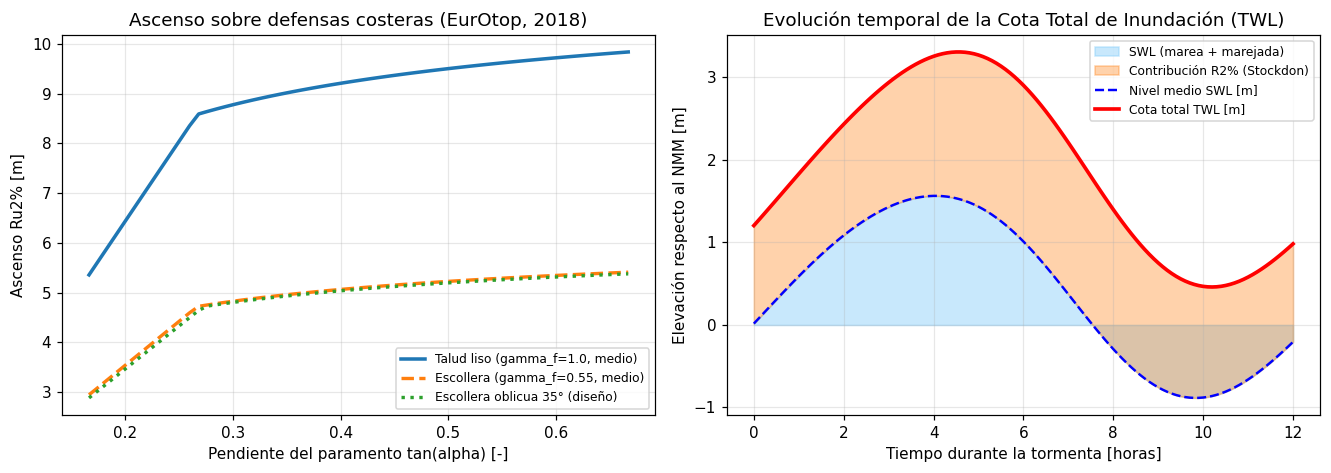

In [3]:
taludes = np.linspace(1.0 / 6.0, 1.0 / 1.5, 60)
Hm0, Tm = 3.0, 9.0

eu_liso = sm.runup.runup_eurotop(Hm0, Tm, taludes, gamma_f=1.0, angle_deg=0.0, method="mean")
eu_escoll = sm.runup.runup_eurotop(Hm0, Tm, taludes, gamma_f=0.55, angle_deg=0.0, method="mean")
eu_oblic = sm.runup.runup_eurotop(Hm0, Tm, taludes, gamma_f=0.55, angle_deg=35.0, method="design")

# Escenario temporal de tormenta: marea semidiurna + marejada meteorológica creciente
horas = np.linspace(0.0, 12.0, 121)
marea = 1.1 * np.sin(2.0 * np.pi * horas / 12.4)
marejada = 0.9 * np.exp(-((horas - 6.0) / 3.0) ** 2)
hs_t = 1.5 + 2.5 * np.exp(-((horas - 6.0) / 3.2) ** 2)

st_t = sm.runup.runup_stockdon(hs_t, T=10.5, slope=0.07)
twl_t = sm.runup.total_water_level(st_t.R2_percent, tide=marea, storm_surge=marejada)

print(f"Máxima TWL durante el pico de tormenta: {np.max(twl_t.twl):.2f} m sobre NMM (SWL_max={np.max(twl_t.swl):.2f} m + R2%={st_t.R2_percent[np.argmax(twl_t.twl)]:.2f} m)")

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12.2, 4.4))

ax1.plot(taludes, eu_liso.R2_percent, lw=2.3, label="Talud liso (gamma_f=1.0, medio)")
ax1.plot(taludes, eu_escoll.R2_percent, "--", lw=2.2, label="Escollera (gamma_f=0.55, medio)")
ax1.plot(taludes, eu_oblic.R2_percent, ":", lw=2.2, label="Escollera oblicua 35° (diseño)")
ax1.set_xlabel("Pendiente del paramento tan(alpha) [-]")
ax1.set_ylabel("Ascenso Ru2% [m]")
ax1.set_title("Ascenso sobre defensas costeras (EurOtop, 2018)")
ax1.grid(alpha=0.3)
ax1.legend(fontsize=8)

ax2.fill_between(horas, 0.0, twl_t.swl, color="lightskyblue", alpha=0.45, label="SWL (marea + marejada)")
ax2.fill_between(horas, twl_t.swl, twl_t.twl, color="tab:orange", alpha=0.35, label="Contribución R2% (Stockdon)")
ax2.plot(horas, twl_t.swl, "b--", lw=1.6, label="Nivel medio SWL [m]")
ax2.plot(horas, twl_t.twl, "r-", lw=2.4, label="Cota total TWL [m]")
ax2.set_xlabel("Tiempo durante la tormenta [horas]")
ax2.set_ylabel("Elevación respecto al NMM [m]")
ax2.set_title("Evolución temporal de la Cota Total de Inundación (TWL)")
ax2.grid(alpha=0.3)
ax2.legend(fontsize=8)

plt.tight_layout()
plt.show()


### Ejercicios propuestos
1. Utilice `sm.runup.compare_runup_models` para comparar los 6 modelos en una playa muy disipativa (`slope=0.012`) frente a una playa reflejante (`slope=0.14`) y analice dónde difieren más.
2. En `runup_eurotop`, introduzca un factor de berma `gamma_b=0.75` y determine cuánto se reduce la cota mínima necesaria de coronamiento de una defensa marítima.
